# Exploring STAC catalogs with `eostac`

This notebook walks through the full workflow:
1. Connect to a public STAC API
2. Search for Sentinel-2 imagery with spatial/temporal/cloud filters
3. Explore the returned GeoDataFrame
4. Visualize item footprints and thumbnails
5. Download a subset of assets concurrently
6. Inspect the downloaded files

In [ ]:
from pathlib import Path

from eostac import STACSource, download_items, search_items, viz

## 1. Connect to a STAC API

We use the public [Earth Search](https://earth-search.aws.element84.com/v1) API hosted by Element84 — no credentials required.

In [2]:
source = STACSource.from_url("https://earth-search.aws.element84.com/v1")

print(f"API:         {source.is_api}")
print(f"Collections: {source.collections[:8]} ...")

API:         True
Collections: ['sentinel-2-pre-c1-l2a', 'cop-dem-glo-30', 'naip', 'cop-dem-glo-90', 'landsat-c2-l2', 'sentinel-2-l2a', 'sentinel-2-l1c', 'sentinel-2-c1-l2a'] ...


## 2. Search for items

Spatial filter: a bounding box over northern Italy / Alps.  
Temporal filter: summer 2023.  
Cloud cover: at most 20 %.

In [3]:
BBOX   = [10.0, 45.5, 12.5, 47.5]   # [west, south, east, north]
DATES  = "2023-06-01/2023-08-31"
LIMIT  = 20

gdf = search_items(
    source,
    collections=["sentinel-2-l2a"],
    bbox=BBOX,
    datetime=DATES,
    max_cloud_cover=20.0,
    limit=LIMIT,
)

print(f"{len(gdf)} items found")

/home/brustt/Documents/Projects/eostac-download/.venv/lib/python3.12/site-packages/pystac_client/item_search.py:300: DoesNotConformTo: Server does not conform to FILTER
  warnings.warn(DoesNotConformTo("FILTER"))


20 items found


## 3. Explore the GeoDataFrame

In [4]:
gdf.columns.tolist()

['geometry',
 'item_id',
 'collection',
 'datetime',
 'cloud_cover',
 'assets',
 'created',
 'platform',
 'constellation',
 'instruments',
 'utm_zone',
 'latitude_band',
 'grid_square',
 'code',
 'sun_azimuth',
 'sun_elevation',
 'degraded_msi_data_percentage',
 'nodata_pixel_percentage',
 'saturated_defective_pixel_percentage',
 'dark_features_percentage',
 'cloud_shadow_percentage',
 'vegetation_percentage',
 'not_vegetated_percentage',
 'water_percentage',
 'unclassified_percentage',
 'medium_proba_clouds_percentage',
 'high_proba_clouds_percentage',
 'thin_cirrus_percentage',
 'snow_ice_percentage',
 'product_type',
 'processing_baseline',
 'product_uri',
 'generation_time',
 'datatake_id',
 'datatake_type',
 'datastrip_id',
 'granule_id',
 'reflectance_conversion_factor',
 'sequence',
 's3_path',
 'payload_id',
 'boa_offset_applied',
 'software',
 'updated']

In [5]:
gdf[["item_id", "collection", "assets", "datetime", "cloud_cover"]].head(10)

,item_id,collection,assets,datetime,cloud_cover
0,S2A_32TNR_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:21.981000+00:00,31.243172
1,S2A_32TPR_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:18.976000+00:00,23.433489
2,S2A_32TQR_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:15.670000+00:00,49.610463
3,S2A_33TUL_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:11.979000+00:00,45.581707
4,S2A_32TNS_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:08.367000+00:00,55.120093
5,S2A_32TPS_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:04.462000+00:00,48.432013
6,S2A_32TQS_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:01.300000+00:00,52.828568
7,S2A_33TUM_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:17:58.112000+00:00,61.465514
8,S2A_32TNT_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:17:57.135000+00:00,78.797102
9,S2A_32TPT_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:17:49.995000+00:00,91.960478


In [6]:
# Cloud cover distribution
gdf["cloud_cover"].describe()

count    20.000000
mean     72.737755
std      25.009478
min      23.433489
25%      52.024042
50%      77.679795
75%      95.305711
max      99.991894
Name: cloud_cover, dtype: float64

In [7]:
# Available asset keys for the first item
first_item_assets = gdf.iloc[0]["assets"]
print("Asset keys:", list(first_item_assets.keys()))

Asset keys: ['aot', 'blue', 'coastal', 'granule_metadata', 'green', 'nir', 'nir08', 'nir09', 'red', 'rededge1', 'rededge2', 'rededge3', 'scl', 'swir16', 'swir22', 'thumbnail', 'tileinfo_metadata', 'visual', 'wvp', 'aot-jp2', 'blue-jp2', 'coastal-jp2', 'green-jp2', 'nir-jp2', 'nir08-jp2', 'nir09-jp2', 'red-jp2', 'rededge1-jp2', 'rededge2-jp2', 'rededge3-jp2', 'scl-jp2', 'swir16-jp2', 'swir22-jp2', 'visual-jp2', 'wvp-jp2']


## 4. Visualize footprints

`plot_footprints` returns a `folium.Map` coloured by any GDF column.

In [8]:
viz.plot_footprints(gdf, column="cloud_cover")

## 5. Visualize thumbnails

Overlays JPEG thumbnails directly on the map — useful to quickly assess scene coverage and cloud patterns before downloading.

In [9]:
viz.plot_thumbnails(gdf, max_items=9)

## 6. Download assets

We pick the 3 clearest scenes and download the RGB bands (`B04`, `B03`, `B02`) plus the Scene Classification Layer (`SCL`).

Downloads run concurrently via `asyncio` + `httpx`.  All 4 × 3 = 12 assets start immediately; `max_workers=8` caps concurrent connections.

In [10]:
subset = gdf.nsmallest(3, "cloud_cover")
subset[["item_id", "collection", "assets", "datetime", "cloud_cover"]]

,item_id,collection,assets,datetime,cloud_cover
1,S2A_32TPR_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:18.976000+00:00,23.433489
0,S2A_32TNR_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:21.981000+00:00,31.243172
3,S2A_33TUL_20230831_0_L2A,sentinel-2-l2a,{'aot': 'https://sentinel-cogs.s3.us-west-2.am...,2023-08-31 10:18:11.979000+00:00,45.581707


In [11]:
viz.plot_footprints(subset)

In [12]:
OUTPUT_DIR = Path("../downloads")

# Select the 3 scenes with lowest cloud cover
subset = gdf.nsmallest(3, "cloud_cover")

result = download_items(
    subset,
    output_dir=OUTPUT_DIR,
    assets=["red", "green", "blue", "scl"],   # Earth Search uses long names
    max_workers=8,
    overwrite=False,
    process=False,
    show_progress=True,
)

print("Done.")

Downloading: 100%|██████████| 12/12 [00:00<00:00, 11790.03file/s]

Done.


## 7. Inspect downloaded files

In [13]:
for _, row in result.iterrows():
    print(f"\n{row['item_id']}  (cloud: {row['cloud_cover']:.1f} %)")
    for key, path in row["local_paths"].items():
        size_mb = path.stat().st_size / 1e6
        print(f"  {key:10s}  {size_mb:6.1f} MB  {path}")


S2A_32TPR_20230831_0_L2A  (cloud: 23.4 %)
  green        227.3 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TPR_20230831_0_L2A/S2A_32TPR_20230831_0_L2A_green.tif
  blue         225.0 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TPR_20230831_0_L2A/S2A_32TPR_20230831_0_L2A_blue.tif
  red          229.9 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TPR_20230831_0_L2A/S2A_32TPR_20230831_0_L2A_red.tif
  scl            4.4 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TPR_20230831_0_L2A/S2A_32TPR_20230831_0_L2A_scl.tif

S2A_32TNR_20230831_0_L2A  (cloud: 31.2 %)
  green         98.1 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TNR_20230831_0_L2A/S2A_32TNR_20230831_0_L2A_green.tif
  scl            2.0 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TNR_20230831_0_L2A/S2A_32TNR_20230831_0_L2A_scl.tif
  blue          97.3 MB  ../downloads/sentinel-2-l2a/2023-08-31/S2A_32TNR_20230831_0_L2A/S2A_32TNR_20230831_0_L2A_blue.tif
  red           99.6 MB  ../downloads/sentinel-2-l2a/2

## 8. Quick raster preview

`viz.quick_view` opens a single raster (local path or remote href) and renders an overview as a `folium.ImageOverlay`.

In [19]:
# Preview the red band of the clearest scene
clearest = result.iloc[0]
red_path = clearest["local_paths"].get("red")
m = None
if red_path:
    m = viz.quick_view(red_path)
else:
    print("red band not downloaded — check asset keys above")


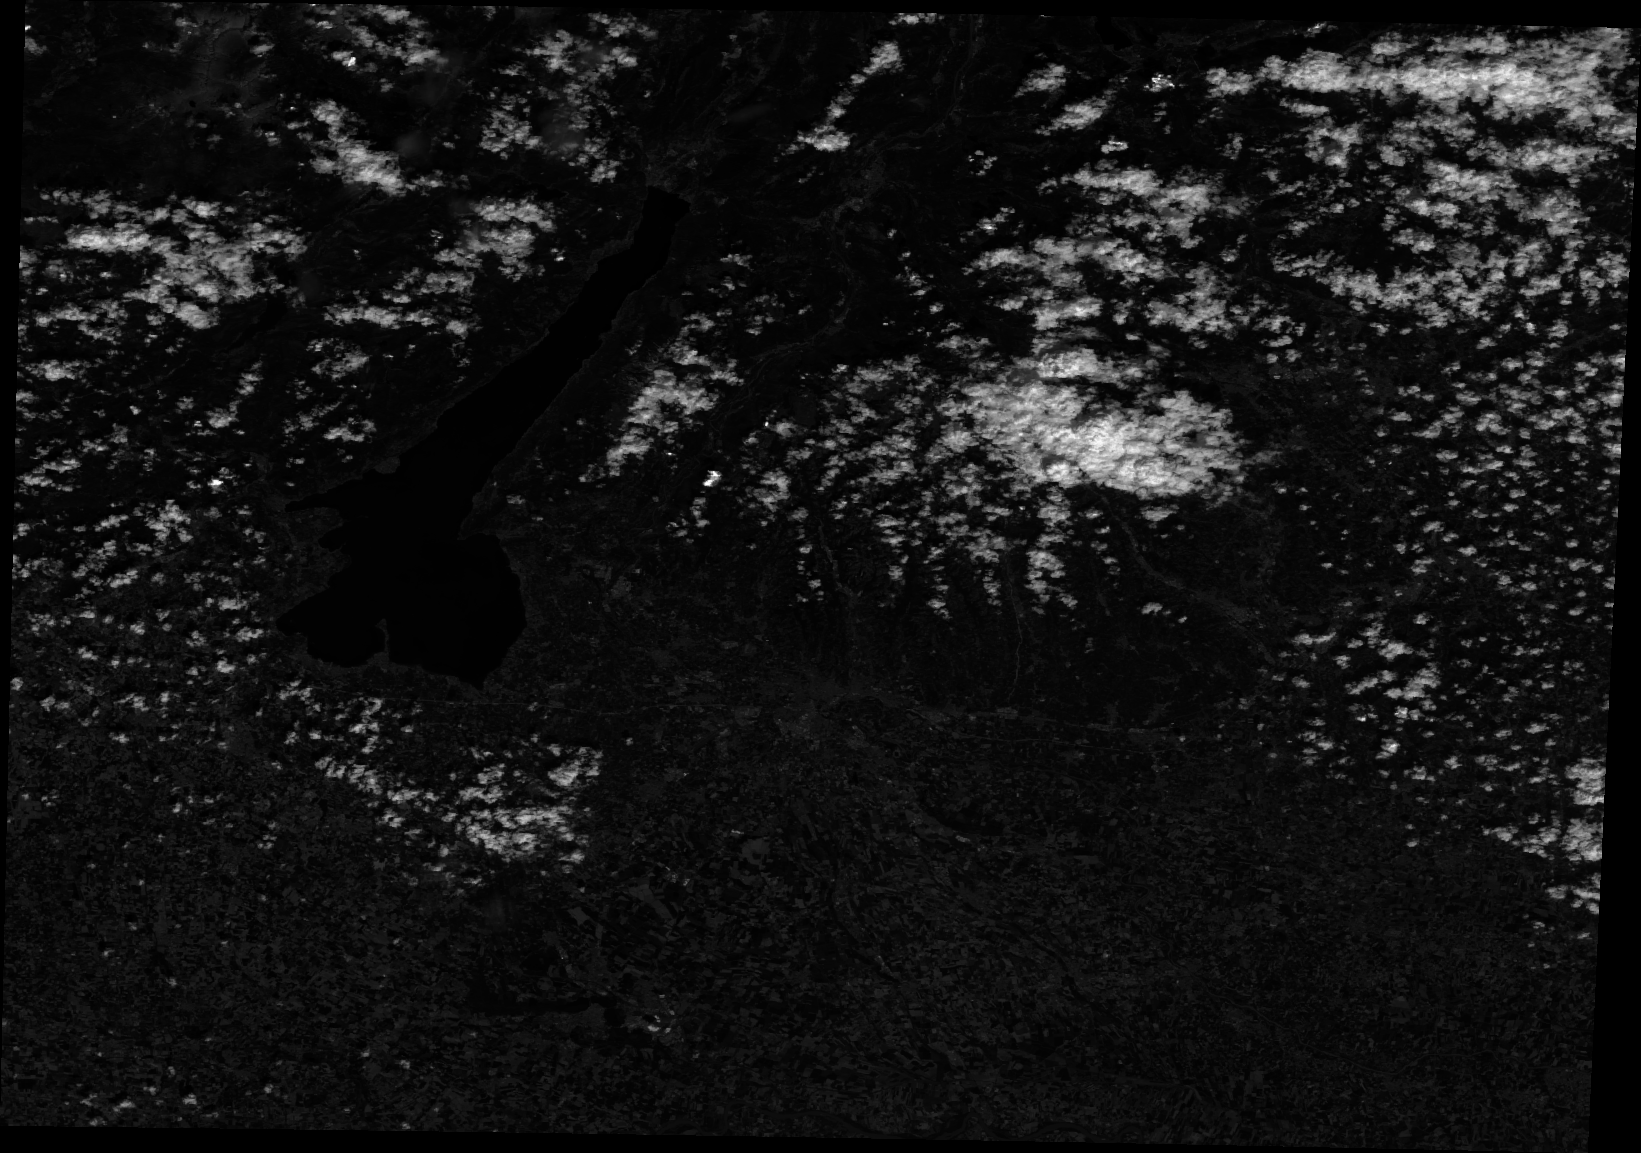

In [20]:
m

## 9. (Optional) Static catalog

`eostac` works identically with local static STAC catalogs — no API server needed.

In [17]:
# Uncomment and point to a local catalog.json:
# local_source = STACSource.from_json("/path/to/catalog.json")
# gdf_local = search_items(local_source, bbox=BBOX, datetime=DATES)
# gdf_local.head()